# 03. Cobertura territorial, contrato de atributos y espacio PCA compartido

Este cuaderno construye la matriz de atributos **no derivados de la
actividad de viajes** por AGEB y un espacio de componentes principales
compartido entre la referencia Golden y las AGEBs candidatas. El PCA es
**descriptivo y transductivo**: se ajusta una sola vez sobre el universo
proyectable y no constituye una evaluación inductiva ni una prueba de
ranking. No se entrenan modelos predictivos ni se afirma métrica
predictiva alguna.

Todas las fuentes provienen de la generación ETL comprometida y verificada,
y del reporte EDA activo cuya identidad queda ligada a la de este análisis.
Los derivados se publican bajo `data/features/<contrato>/<análisis>/`,
separados de la generación ETL inmutable.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.fe03_analysis import CONFIG, FEATURE_NAMES, load_inputs, analyze
from V3.src.fe03_publication import stage_results

GREEN, GRAY, BLUE = "#004731", "#546E7A", "#0D47A1"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data)
report = result["report"]
features, scores = result["features"], result["scores"]
loadings, centroid = result["loadings"], result["centroid"]
assert isinstance(features, gpd.GeoDataFrame)
display(pd.DataFrame([{
    "contract_id": report["contract_id"],
    "analysis_version": report["schema_version"],
    "n_agebs": len(features),
    "projectable_agebs": report["feature_matrix"]["projectable_agebs"],
    "n_features": report["feature_matrix"]["n_features_raw"],
}]))

,contract_id,analysis_version,n_agebs,projectable_agebs,n_features
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-features-2,2452,2402,18


## 1. Cobertura territorial y escenario de candidatas

Los buffers son **euclidianos proyectados de 500 m** en EPSG:32614. No son
áreas de servicio caminables ni geodésicas, y **no resuelven el MAUP**.
La regla «fracción cubierta < 15%» es un **escenario de planificación**;
una cobertura igual o mayor al 15% no constituye saturación ni evidencia
de suficiencia de servicio.

El diagnóstico distingue tres magnitudes que no deben mezclarse: el
**conteo territorial** de AGEBs candidatas, el **conteo proyectable**
(las candidatas que además cumplen el contrato de atributos) y las
**participaciones de área** respecto al polígono total. La sensibilidad
reporta radios y umbrales alternativos con el mismo criterio.

,value
coverage_method,Euclidean projected buffer; not a walking serv...
maup_resolved,False
buffer_radius_m,500
buffer_area_km2,87.679684
pure_candidate_threshold,0.15
total_agebs,2452
territorial_candidates_count,2111
projectable_candidates_count,2064
unprojectable_candidates_count,47
covered_or_consolidated_count,341


,radius_m,area_threshold,candidate_count,candidate_ageb_share,candidate_area_share
0,300,0.05,2129,0.868271,0.935657
1,300,0.15,2147,0.875612,0.941197
2,300,0.30,2164,0.882545,0.944640
3,400,0.05,2115,0.862561,0.933492
4,400,0.15,2127,0.867455,0.936356
5,400,0.30,2140,0.872757,0.940489
6,500,0.05,2100,0.856444,0.930635
7,500,0.15,2111,0.860930,0.933231
8,500,0.30,2126,0.867047,0.937767
9,800,0.05,2032,0.828711,0.920646


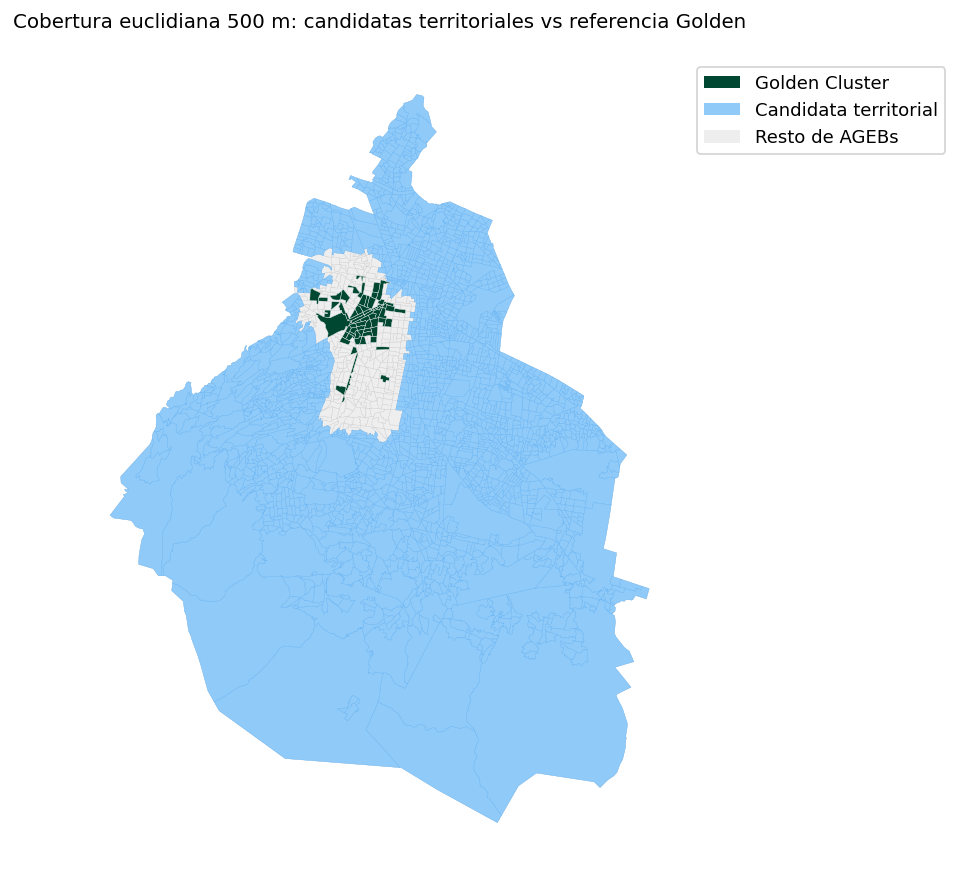

**Resultado.** 2,111 AGEBs candidatas territoriales, de las cuales 2,064 son proyectables; participación en conteo 86.09% y en área 93.32%.

In [2]:
maup = report["maup_mitigation"]
display(pd.Series(maup, name="value").to_frame())
display(result["maup_sensitivity"])
fig, ax = plt.subplots(figsize=(9, 8))
features.plot(ax=ax, color="#EEEEEE", edgecolor="#CCCCCC", linewidth=0.2)
features[features.is_candidata_territorial].plot(
    ax=ax, color="#90CAF9", edgecolor="#64B5F6", linewidth=0.2)
features[features.is_golden_cluster].plot(
    ax=ax, color=GREEN, edgecolor="white", linewidth=0.2)
ax.set_title(f"Cobertura euclidiana {CONFIG['buffer_radius_m']} m: "
             "candidatas territoriales vs referencia Golden")
ax.legend(handles=[
    Patch(facecolor=GREEN, label="Golden Cluster"),
    Patch(facecolor="#90CAF9", label="Candidata territorial"),
    Patch(facecolor="#EEEEEE", label="Resto de AGEBs"),
], loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_axis_off(); plt.show()
display(Markdown(
    f"**Resultado.** {maup['territorial_candidates_count']:,} AGEBs "
    f"candidatas territoriales, de las cuales "
    f"{maup['projectable_candidates_count']:,} son proyectables; "
    f"participación en conteo {maup['candidate_ageb_share']:.2%} y en "
    f"área {maup['candidate_area_share']:.2%}."
))

**Nota metodológica: ¿por qué el umbral de cobertura es 15% y no 50% o mayor ?**

El umbral de cobertura no pretende medir si una AGEB está *bien servida*;
detecta si la red **ya toca el polígono**. Son preguntas distintas:

- Una AGEB con 30% de su área dentro de un buffer está *sub-servida* — la
  mayor parte de sus residentes queda fuera del radio de 500 m.
- Pero también está *conectada a la red existente*: el buffer que la cubre
  parcialmente demuestra que la frontera operativa ya la alcanzó.

El Motor 1 prioriza **expansión de frontera**: territorio donde el servicio
aún no existe, adyacente al clúster consolidado — coherente con el
principio de contigüidad de la red (una estación nueva solo genera viajes
si conecta con el sistema donde el usuario debe devolver la bicicleta).
Para esa decisión, el universo relevante son las AGEBs que la red
prácticamente no ha tocado.

**La elección es empíricamente robusta.** La cobertura por AGEB es
fuertemente bimodal: 2,082 AGEBs tienen cobertura cero y 281 tienen ≥80%.
La banda intermedia es pequeña —solo 29 AGEBs caen entre 15% y 50%— por
lo que el universo de candidatas apenas cambia al mover el umbral
(2,111 con 15% frente a 2,140 con 50%). La tabla de sensibilidad publicada
documenta esta estabilidad entre 5% y 30%: la clasificación no depende de
un valor ajustado a conveniencia.

**El costo de un umbral alto es asimétrico.** Las AGEBs de la banda
15–50% son polígonos en el borde de la red; por contigüidad, son
ambientalmente las más parecidas a las AGEBs Golden. Incluirlas en el
pool de candidatas las colocaría en lo alto del ranking de similitud y el
motor recomendaría estaciones nuevas donde el 30–49% del territorio ya
tiene cobertura —canibalización parcial, el modo de falla que este diseño
busca evitar. Excluirlas del pool de frontera no las elimina del análisis:
conservan sus atributos y sus componentes PCA, y el problema que
representan —densificación dentro de un polígono parcialmente servido— es
una decisión distinta a la de extender la red.

**Reconocimiento explícito.** Las 29 AGEBs con cobertura entre 15% y 50%
concentran ~110,528 residentes conocidos que están, efectivamente,
sub-servidos. Este trabajo los reporta como tal en lugar de declararlos
cubiertos; su tratamiento corresponde a un análisis de densificación
(*infill*), no a la expansión de frontera que el Motor 1 resuelve.


## 2. Filtros de fuente y contrato exacto de atributos

- **DENUE**: se conservan únicamente altas de sectores terciarios SCIAN
  explícitos con **fecha de alta conocida hasta 2025**, leídas del
  directorio edición 2026. Es un **proxy retrospectivo**, no la
  reconstrucción del stock histórico: no recupera cierres, cambios de
  actividad ni reubicaciones previas.
- **GTFS**: la distancia a Metro/Metrobús se filtra mediante vínculos
  aceptados stop_times → trips → routes y el **calendario de servicio
  con cobertura declarada en 2025**; no se mide servicio observado ni
  acceso caminable.
- **Infraestructura ciclista**: solo tramos en estado «En operación»;
  las tipologías incluidas son **heterogéneas y no exclusivamente
  segregadas**.
- **Censo 2020**: las tasas residenciales conservan sus denominadores
  documentados; valores censales crudos preservados.

La tabla siguiente es el contrato completo de los atributos usados por
el espacio compartido: fuente, unidad, numerador, denominador,
transformación y política de faltantes.

In [3]:
sources = report["source_filters"]
for name in ["denue", "gtfs", "cycling"]:
    display(Markdown(f"**{name}**"))
    display(pd.Series(sources[name], name="value").to_frame())
contract = pd.DataFrame(report["feature_matrix"]["feature_contract"])
assert len(contract) == len(FEATURE_NAMES)
display(contract)

**denue**

,value
input_records,462732
selected_tertiary_records,419221
matched_tertiary_records,417864
selected_without_geometry,1357
registration_after_2025,9627
registration_unknown_excluded,36
nontertiary_known_registration_through_2025_excluded,33848
open_band_selected_records,1612
open_band_assumed_employees,300
snapshot_years,[2026]


**gtfs**

,value
agencies,"[METRO, MB]"
eligible_unique_stop_ids,568
stop_ids_by_agency,"{'MB': 373, 'METRO': 195}"
calendar_rule,"has_2025_service; declared coverage, not obser..."
distance_method,AGEB centroid to eligible stop; Euclidean in E...
centroids_outside_polygon,55
historical_stop_positions_reconstructed,False
walking_access_measured,False


**cycling**

,value
input_segments,651
included_segments,514
excluded_segments,137
included_status,En operacion
excluded_status_counts,"{'Requiere mantenimiento': 74, 'Fuera de servi..."
included_typologies,"{'Ciclovia': 221, 'Sendero compartido': 85, 'C..."
length_inside_agebs_km,482.162757
segregated_infrastructure_only,False
operation_verified_in_field,False


,name,source,unit,numerator,denominator,transform,missing_policy
0,densidad_pob_km2,Censo 2020 + geometry,inhabitants/km2,POBTOT,area_km2,log1p,must be observed or defined by source convention
1,POBTOT,Censo 2020,inhabitants,POBTOT,None,log1p,must be observed or defined by source convention
2,pct_edad_productiva,Censo 2020,fraction,POB15_64,POBTOT,identity,median only with applicable positive denominator
3,pct_jovenes_18_24,Censo 2020,fraction,P_18A24,POBTOT,identity,median only with applicable positive denominator
4,pct_adultos_mayores,Censo 2020,fraction,P_60YMAS,POBTOT,identity,median only with applicable positive denominator
5,grado_escolar_prom,Censo 2020,school years,GRAPROES,None,identity,must be observed or defined by source convention
6,tasa_ocupacion,Censo 2020,fraction,POCUPADA,PEA,identity,median only with applicable positive denominator
7,pct_viviendas_internet,Censo 2020,fraction,VPH_INTER,TVIVHAB,identity,median only with applicable positive denominator
8,pct_viviendas_bici,Censo 2020,fraction,VPH_BICI,TVIVHAB,identity,median only with applicable positive denominator
9,pct_viviendas_auto,Censo 2020,fraction,VPH_AUTOM,TVIVHAB,identity,median only with applicable positive denominator


## 3. Faltantes, elegibilidad y política de imputación

Las AGEBs rurales y las filas con tasas residenciales estructuralmente
indefinidas (denominador poblacional, de vivienda o laboral ausente) se
**excluyen del ajuste**, no se convierten en perfiles de «residente
promedio» fabricados. Las exclusiones por causas no residenciales
**tampoco significan demanda potencial cero**.

Cuando falta un numerador pero su denominador es aplicable y positivo,
la mediana imputa la **tasa derivada** —nunca sustituye el numerador en
sí—; los **valores crudos se preservan** junto con los indicadores de
faltante e imputación para auditoría posterior.

In [4]:
fm = report["feature_matrix"]
summary_keys = ["projectable_agebs", "unprojectable_agebs",
                "rural_nans_preserved_count", "imputed_rows",
                "imputed_candidate_rows", "imputed_golden_rows",
                "imputed_cells"]
display(pd.Series({k: fm[k] for k in summary_keys}, name="value").to_frame())
display(pd.Series(sources["exclusion_reason_counts_nonexclusive"],
                  name="n_agebs").to_frame())
display(pd.Series(fm["imputed_cells_by_feature"],
                  name="missing_cells").to_frame())

,value
projectable_agebs,2402
unprojectable_agebs,50
rural_nans_preserved_count,22
imputed_rows,23
imputed_candidate_rows,22
imputed_golden_rows,0
imputed_cells,41


,n_agebs
nonurban,22
population_missing,22
no_resident_population,17
schooling_missing,32
undefined_household_denominator,40
undefined_labour_denominator,50
nonimputable_feature_missing,32


,missing_cells
densidad_pob_km2,0
POBTOT,0
pct_edad_productiva,0
pct_jovenes_18_24,4
pct_adultos_mayores,7
grado_escolar_prom,0
tasa_ocupacion,0
pct_viviendas_internet,5
pct_viviendas_bici,15
pct_viviendas_auto,10


## 4. Espacio PCA compartido y lectura de PC1

El PCA se ajusta una vez con las filas proyectables y aplica la **misma
canalización** (contrato → mediana → estandarización → componentes) a
Golden y candidatas, garantizando comparabilidad en una base ortonormal.
La retención se define por el objetivo de varianza acumulada declarado
en la configuración.

**PC1 — Eje de Equipamiento y Composición Socioeconómica Residencial.**
Los coeficientes mostrados son cargas del vector propio con su signo;
**no son efectos causales, ni medidas de centralidad ni de atracción**.
Advertencia de sesgo: la similitud en este eje puede replicar contextos
afluentes —el ingreso no se observa directamente— sin optimizar el
servicio de transporte.

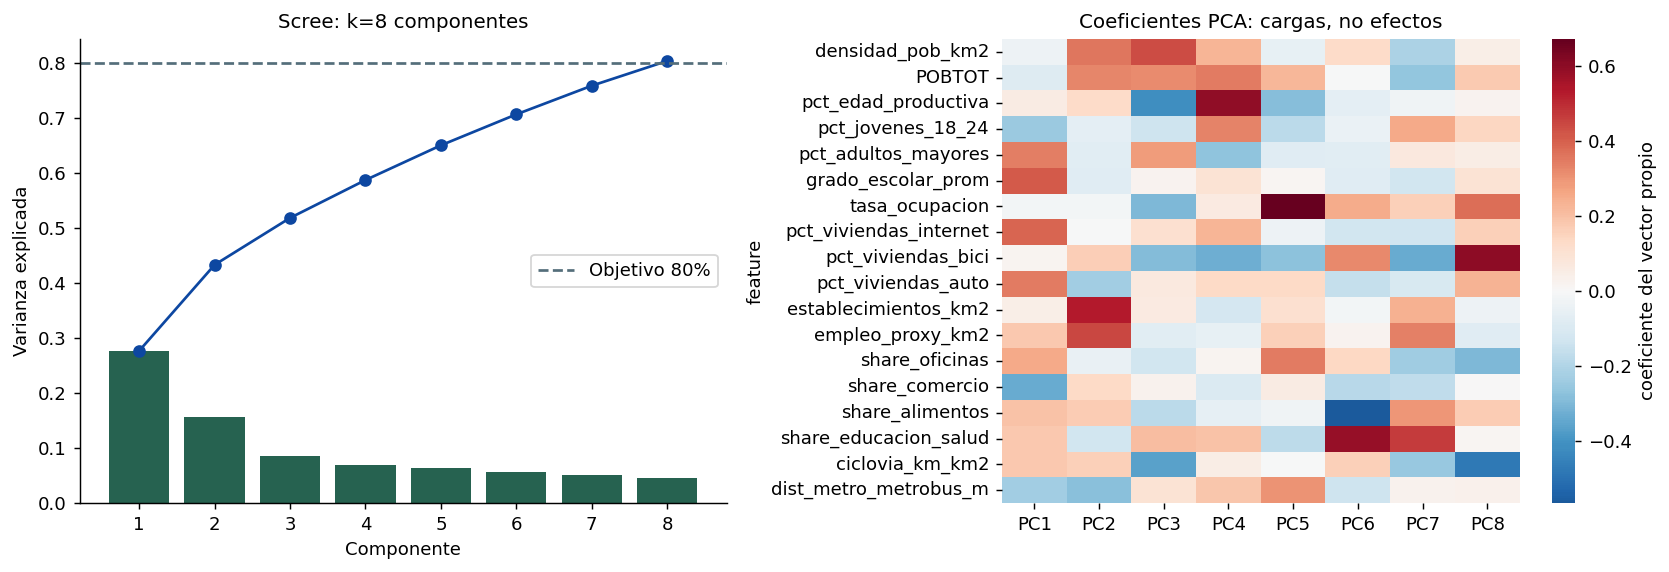

,coeficiente_PC1
grado_escolar_prom,0.409412
pct_viviendas_internet,0.386898
pct_viviendas_auto,0.345990
pct_adultos_mayores,0.342257
share_comercio,-0.334855


**Resultado.** 8 componentes explican el 80.37% de la varianza; los coeficientes principales de PC1 se muestran con signo.

In [5]:
pca = report["pca_reduction"]
individual = np.asarray(pca["individual_variance_explained"], dtype=float)
order = np.arange(1, len(individual) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(order, individual, color=GREEN, alpha=0.85)
axes[0].plot(order, np.cumsum(individual), marker="o", color=BLUE)
axes[0].axhline(CONFIG["variance_target"], color=GRAY, ls="--",
                label=f"Objetivo {CONFIG['variance_target']:.0%}")
axes[0].set(xlabel="Componente", ylabel="Varianza explicada",
            title=f"Scree: k={pca['k_components_80_pct']} componentes")
axes[0].legend()
sns.heatmap(loadings, cmap="RdBu_r", center=0, ax=axes[1],
            cbar_kws={"label": "coeficiente del vector propio"})
axes[1].set_title("Coeficientes PCA: cargas, no efectos")
plt.tight_layout(); plt.show()
display(pd.Series(pca["top_pc1_signed_coefficients"],
                  name="coeficiente_PC1").to_frame())
display(Markdown(
    f"**Resultado.** {pca['k_components_80_pct']} componentes explican "
    f"el {pca['cumulative_variance_explained']:.2%} de la varianza; "
    "los coeficientes principales de PC1 se muestran con signo."
))

## 5. Referencia Golden y distancias en el espacio compartido

El centroide Golden usa **un peso igual por AGEB proyectable**, no por
estación. La similitud por **dirección (coseno)** difiere de la
similitud por **magnitud (euclidiana)**; ambas se derivan de la misma
base, por lo que compartir el espacio **no prueba por sí solo un
ranking válido**. La covarianza de referencia y el umbral de dominio
para distancias de Mahalanobis quedan pendientes de calibración
explícita.

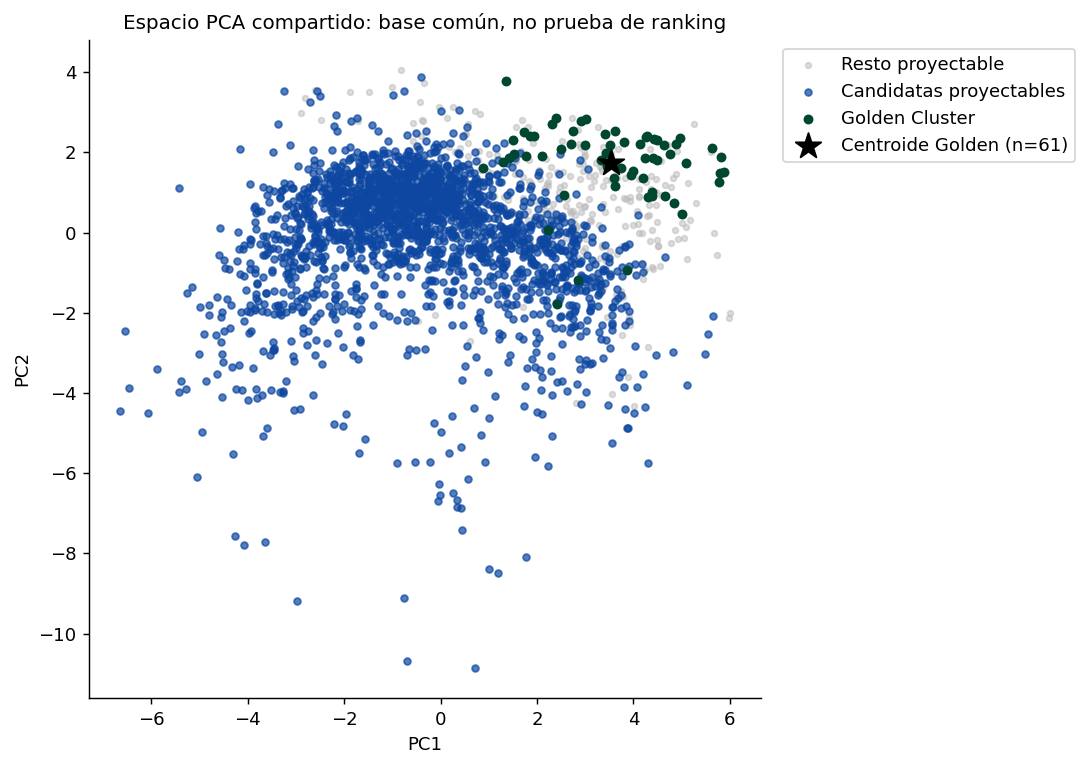

In [6]:
pc_names = [c for c in scores.columns if str(c).startswith("PC")]
x_name = pc_names[0]
y_name = pc_names[1] if len(pc_names) > 1 else pc_names[0]
rest = scores.is_projectable & ~scores.is_golden_cluster         & ~scores.is_candidata_proyectable
cand = scores.is_projectable & scores.is_candidata_proyectable         & ~scores.is_golden_cluster
gold = scores.is_projectable & scores.is_golden_cluster
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(scores.loc[rest, x_name], scores.loc[rest, y_name],
           s=10, color="#BBBBBB", alpha=0.5, label="Resto proyectable")
ax.scatter(scores.loc[cand, x_name], scores.loc[cand, y_name],
           s=14, color=BLUE, alpha=0.7, label="Candidatas proyectables")
ax.scatter(scores.loc[gold, x_name], scores.loc[gold, y_name],
           s=20, color=GREEN, label="Golden Cluster")
ax.scatter(centroid[x_name].iloc[0], centroid[y_name].iloc[0],
           marker="*", s=220, color="black",
           label=f"Centroide Golden (n={int(centroid['n_golden_agebs'].iloc[0])})")
ax.set(xlabel=x_name, ylabel=y_name,
       title="Espacio PCA compartido: base común, no prueba de ranking")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout(); plt.show()

## 6. Alcance, validación pendiente y publicación

Este ajuste es **global, descriptivo y transductivo**. Para la evaluación
inductiva del cuaderno 04 el preprocesamiento (imputación, escalamiento,
PCA), la selección Golden por P85 y el centroide deberán reajustarse
**dentro de cada pliegue de entrenamiento**, junto con bloques espaciales
o buffers entre particiones: GroupKFold por AGEB por sí solo no aísla
polígonos vecinos. La sensibilidad del ranking al umbral P85 queda
**pendiente**; no se afirma haberla ejecutado.

**Reutilización del espacio.** La canalización publicada puede cargarse
una vez activado el reporte, sin reajuste, sobre atributos nuevos que
cumplan el mismo contrato de 20 columnas de entrada (las 18
características brutas más `TVIVHAB` y `PEA` como denominadores de
elegibilidad; no son coordenadas ni identificadores):

```python
from V3.src.fe03_analysis import INPUT_COLUMNS
from V3.src.fe03_publication import load_feature_pipeline
pipeline = load_feature_pipeline(V3_DIR)          # solo tras activación
scores_nuevos = pipeline.transform(nuevos_atributos[INPUT_COLUMNS])
```

Los derivados se publican fuera de la generación ETL, con identidad
ligada al código, las fuentes y el reporte EDA activo; la auditoría
activa se actualiza solo después de guardar el cuaderno ejecutado.

In [7]:
display(pd.DataFrame({"pending_validation": report["pending_validation"]}))
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Atributos, espacio compartido y canalización "
                 "publicados con verificación de integridad."))
display(JSON({"fe03_report_path": report_path.relative_to(V3_DIR).as_posix()}))

,pending_validation
0,"Fold-local preprocessing, Golden selection and..."
1,Spatial blocks/buffers; GroupKFold alone does ...
2,"Ranking sensitivity to imputation, PCA truncat..."
3,Nonresidential candidate representation; exclu...
4,Physical network connectivity and spatial out-...
5,Historical source availability and equity-vers...
6,Declared Mahalanobis reference covariance and ...


**Cierre.** Atributos, espacio compartido y canalización publicados con verificación de integridad.

<IPython.core.display.JSON object>